# WorkBuddy 100篇内容分析

## tl;dr

本笔记本对《WorkBuddy 100种用法》完整100篇文章进行可重复分析。最终结论以执行后的统计表与图为准：重点检查连续发布、主题结构、标题钩子、篇幅与视觉证据密度，以及哪些内容形态更适合迁移为课程销售型“百问百答”。

## Context & Methods

分析单位为单篇文章，共100篇；时间范围按合集发布时间，为2026年4月1日至2026年7月9日（Asia/Shanghai）。原始数据来自微信公开合集页和单篇公开文章页，本地保留HTML、清洗正文、封面和图片链接。

### Key Assumptions

- 五大主题为人工主分类，每篇只归入一个最主要主题，用于观察内容组合，不代表作者官方标签。
- 标题钩子和能力标签为多标签规则识别，同一篇可命中多个标签，因此占比不应相加为100%。
- “视频适配度”是选题筛选启发式评分，不是播放量预测；合集没有提供可靠的单篇阅读/转化数据，因此不比较内容效果高低。
- 正文字数按去除空白后的字符数计算；图片数按正文中的不同图片链接统计。

## Data

### 1. Load Data

In [1]:
from pathlib import Path
import json, re, statistics
from datetime import datetime, timezone, timedelta
from html.parser import HTMLParser

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name != 'workbuddy_100_research':
    ROOT = ROOT / 'workbuddy_100_research'
ARCHIVE = ROOT / 'archive'
OUTPUT = ROOT / 'analysis_outputs'
OUTPUT.mkdir(exist_ok=True)

records = json.loads((ARCHIVE / 'article_index.json').read_text(encoding='utf-8'))
df = pd.DataFrame(records)
len(df), df['status'].value_counts().to_dict()

(100, {'ok': 100})

### 2. Validate Inputs

In [2]:
assert len(df) == 100, f'Expected 100 articles, got {len(df)}'
assert df['position'].nunique() == 100
assert df['msgid'].nunique() == 100
assert (df['status'] == 'ok').all()
assert df['body'].str.len().min() > 80

CN = timezone(timedelta(hours=8))
df['published_at'] = pd.to_datetime(df['create_time'].astype(int), unit='s', utc=True).dt.tz_convert('Asia/Shanghai')
df['publish_date'] = df['published_at'].dt.date
expected_dates = pd.date_range(df['published_at'].min().date(), df['published_at'].max().date(), freq='D').date
missing_dates = sorted(set(expected_dates) - set(df['publish_date']))
duplicate_dates = df.loc[df['publish_date'].duplicated(keep=False), 'publish_date'].astype(str).tolist()

quality_summary = {
    'rows': len(df),
    'unique_articles': int(df['msgid'].nunique()),
    'failed_articles': int((df['status'] != 'ok').sum()),
    'start_date': str(df['publish_date'].min()),
    'end_date': str(df['publish_date'].max()),
    'calendar_days_inclusive': len(expected_dates),
    'missing_publish_dates': missing_dates,
    'duplicate_publish_dates': duplicate_dates,
    'total_clean_chars': int(df['char_count'].sum()),
    'total_inline_images': int(df['image_count'].sum()),
}
quality_summary

{'rows': 100,
 'unique_articles': 100,
 'failed_articles': 0,
 'start_date': '2026-04-01',
 'end_date': '2026-07-09',
 'calendar_days_inclusive': 100,
 'missing_publish_dates': [],
 'duplicate_publish_dates': [],
 'total_clean_chars': 234989,
 'total_inline_images': 866}

### 3. Add Human-Reviewed Theme Labels

In [3]:
category_positions = {
    '内容创作与传播': [1,2,4,5,15,19,24,29,32,38,39,41,44,47,51,56,58,65,68,71,72,75,79,80,84,94,97,98,99],
    '开发与产品实现': [3,6,10,11,16,18,20,21,22,23,27,31,33,37,46,50,52,54,55,64,67,77,83,88,89,91,93,95],
    '办公与数据自动化': [7,8,9,13,14,17,25,30,40,42,43,49,57,62,63,78,87,90,92],
    '研究、知识与决策': [26,34,35,36,45,48,53,59,60,66,69,73,74,76,82,85,86,96,100],
    '生活与个人效率': [12,28,61,70,81],
}
flat = [position for positions in category_positions.values() for position in positions]
assert len(flat) == 100 and len(set(flat)) == 100 and set(flat) == set(range(1, 101))
category_by_position = {position: category for category, positions in category_positions.items() for position in positions}
df['primary_category'] = df['position'].map(category_by_position)
df['primary_category'].value_counts()

primary_category
内容创作与传播     29
开发与产品实现     28
办公与数据自动化    19
研究、知识与决策    19
生活与个人效率      5
Name: count, dtype: int64

### 4. Engineer Title, Narrative, and Capability Features

In [4]:
prefix_re = re.compile(r'^WorkBuddy\s*100\s*种用法\s*#\s*\d+\s*[｜|_—:-]*\s*', re.I)
df['title_tail'] = df['title_actual'].map(lambda value: prefix_re.sub('', value).strip())

hook_patterns = {
    '疑问/痛点开场': r'[？?]|不会|收不到|忘|乱成|报错|警告|快满|过期',
    '明确时间承诺': r'\d+(?:\.\d+)?\s*(?:秒|分钟|小时|天)|半小时|半天|一秒',
    '一句话/一键/直接': r'一句话|一键|直接|丢一句话|扔一句话|把需求一丢',
    '具体数字或清单': r'(?<!#)(?<!100种用法)\d+',
    '翻车/踩坑/反转': r'翻车|踩坑|终于|折腾|吓一跳|却|无数|过时|换了个办法',
    '零代码/低门槛': r'零代码|零操作|不用敲命令|不会部署|不用积分',
    '上线/发布/可访问': r'上线|部署|发布|全网可访问|推到公众号草稿箱',
    '第一人称真实经历': r'我|朋友|同事|外甥|给娃|楼下|昨天|顺手',
}
for label, pattern in hook_patterns.items():
    df[label] = df['title_tail'].str.contains(pattern, regex=True, case=False)

capability_patterns = {
    '内容与视觉': r'公众号|小红书|知乎|视频|PPT|海报|封面|配图|生图|表情包|摄影|排版|草稿箱',
    '网页/应用/部署': r'网站|网页|系统|App|小程序|后台|官网|博客|部署|上线|EdgeOne|Cloudflare|HTML|CSS',
    '数据/文件/办公': r'Excel|PDF|数据|会议|纪要|问卷|文件|磁盘|目录|报表|看板|飞书|钉钉|邮箱',
    '专家/多Agent': r'专家|Agent|团队|圆桌|分析师',
    'Skill/MCP/连接器': r'Skill|MCP|连接器|接口|API|接入',
    '自动化/定时任务': r'自动|定时|签到|推送|情报|日报|晨报|流水线',
    '研究与决策': r'研究|分析|法律|合同|年报|股票|基金|竞品|行业|报价|风险|报志愿|职业|操作清单',
    '生活场景': r'亲子|娃|孩子|麦当劳|瑞幸|膳食|出行|咖啡|学习游戏|数独',
}
combined = df['title_tail'] + '\n' + df['body']
for label, pattern in capability_patterns.items():
    df[label] = combined.str.contains(pattern, regex=True, case=False)

df['has_series_cta'] = df['body'].str.contains(r'这是\s*WorkBuddy\s*100种用法第|这是WorkBuddy 100种用法的第', regex=True, case=False)
df['has_follow_cta'] = df['body'].str.contains('关注我，一起探索WorkBuddy的更多玩法', regex=False)
df['has_daily_claim'] = df['body'].str.contains('持续日更', regex=False)
df['body_first_person'] = df['body'].str[:500].str.contains(r'我|朋友|同事|外甥|娃|孩子|楼下|昨天', regex=True)

df['video_score'] = (
    df['image_count'].ge(6).astype(int) * 2
    + df['上线/发布/可访问'].astype(int) * 2
    + df['明确时间承诺'].astype(int)
    + df['第一人称真实经历'].astype(int)
    + df['翻车/踩坑/反转'].astype(int) * 2
    + df['primary_category'].eq('生活与个人效率').astype(int)
    + df['char_count'].between(900, 3200).astype(int)
)

feature_columns = list(hook_patterns) + list(capability_patterns) + [
    'has_series_cta', 'has_follow_cta', 'has_daily_claim', 'body_first_person', 'video_score'
]
df[['position', 'title_tail', 'primary_category', 'char_count', 'image_count'] + feature_columns].head(8)

,position,title_tail,primary_category,char_count,image_count,疑问/痛点开场,明确时间承诺,一句话/一键/直接,具体数字或清单,翻车/踩坑/反转,...,专家/多Agent,Skill/MCP/连接器,自动化/定时任务,研究与决策,生活场景,has_series_cta,has_follow_cta,has_daily_claim,body_first_person,video_score
0,1,公众号封面图，AI一秒给我5张选,内容创作与传播,1713,9,False,True,False,True,False,...,False,False,True,True,False,False,False,False,True,5
1,2,公众号配图背景乱？AI一键批量统一,内容创作与传播,1435,6,True,False,True,False,False,...,False,False,True,True,False,False,False,False,True,3
2,3,零代码！语聊20分钟，2048游戏直接上线,开发与产品实现,1122,8,False,True,True,True,False,...,False,False,False,False,False,False,False,False,True,6
3,4,用AI做PPT，一键完成养虾第五个任务,内容创作与传播,1206,11,False,False,True,False,False,...,True,False,True,True,False,False,False,False,True,3
4,5,即梦 AI 接口，自动生成公众号封面图,内容创作与传播,2319,9,False,False,False,False,False,...,False,True,True,True,False,False,False,False,True,3
5,6,零代码！30分钟用AI做个MBTI测试网站，直接上线,开发与产品实现,2558,7,False,True,True,True,False,...,False,True,True,True,False,False,False,False,True,6
6,7,定时任务收不到结果？邮件推送一键搞定,办公与数据自动化,1966,10,True,False,True,False,False,...,False,True,True,True,False,False,False,False,True,3
7,8,定时任务直接推微信！PushPlus 秒通知方案,办公与数据自动化,1327,7,False,False,True,False,False,...,False,True,True,False,False,False,False,False,True,3


## Results

### 5. Corpus Scale and Cadence

In [5]:
scale_summary = pd.DataFrame({
    'metric': ['文章数', '连续自然日', '清洗后正文字符', '正文图片链接', '单篇字符中位数', '单篇图片中位数'],
    'value': [len(df), len(expected_dates), int(df['char_count'].sum()), int(df['image_count'].sum()),
              int(df['char_count'].median()), float(df['image_count'].median())]
})
scale_summary

,metric,value
0,文章数,100.0
1,连续自然日,100.0
2,清洗后正文字符,234989.0
3,正文图片链接,866.0
4,单篇字符中位数,2259.0
5,单篇图片中位数,8.0


### 6. Topic Mix

In [6]:
category_order = ['内容创作与传播', '开发与产品实现', '办公与数据自动化', '研究、知识与决策', '生活与个人效率']
category_summary = (df['primary_category'].value_counts().reindex(category_order).rename('articles').reset_index()
                    .rename(columns={'primary_category':'category'}))
category_summary['share_pct'] = category_summary['articles'] / len(df) * 100
category_summary

,category,articles,share_pct
0,内容创作与传播,29,29.0
1,开发与产品实现,28,28.0
2,办公与数据自动化,19,19.0
3,研究、知识与决策,19,19.0
4,生活与个人效率,5,5.0


findfont: Failed to find font weight bold, now using 400.


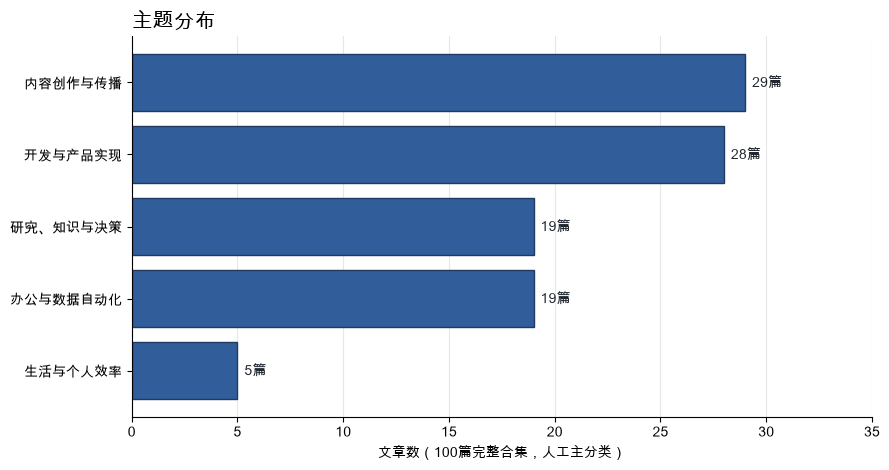

In [7]:
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_data = category_summary.sort_values('articles')
bars = ax.barh(plot_data['category'], plot_data['articles'], color='#315E9B', edgecolor='#203B5F')
ax.bar_label(bars, labels=[f'{v}篇' for v in plot_data['articles']], padding=5, color='#20262E')
ax.set_title('主题分布', loc='left', fontsize=15, fontweight='bold')
ax.set_xlabel('文章数（100篇完整合集，人工主分类）')
ax.set_xlim(0, max(plot_data['articles']) + 6)
ax.grid(axis='x', color='#E5E7EB', linewidth=0.8)
ax.set_axisbelow(True)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT / '主题分布.png', dpi=180, bbox_inches='tight')
plt.show()

### 7. Title Hook Mix

In [8]:
hook_summary = pd.DataFrame([
    {'hook': label, 'articles': int(df[label].sum()), 'share_pct': float(df[label].mean() * 100)}
    for label in hook_patterns
]).sort_values('articles', ascending=False)
hook_summary

,hook,articles,share_pct
7,第一人称真实经历,39,39.0
3,具体数字或清单,38,38.0
2,一句话/一键/直接,31,31.0
1,明确时间承诺,24,24.0
0,疑问/痛点开场,19,19.0
6,上线/发布/可访问,18,18.0
4,翻车/踩坑/反转,9,9.0
5,零代码/低门槛,7,7.0


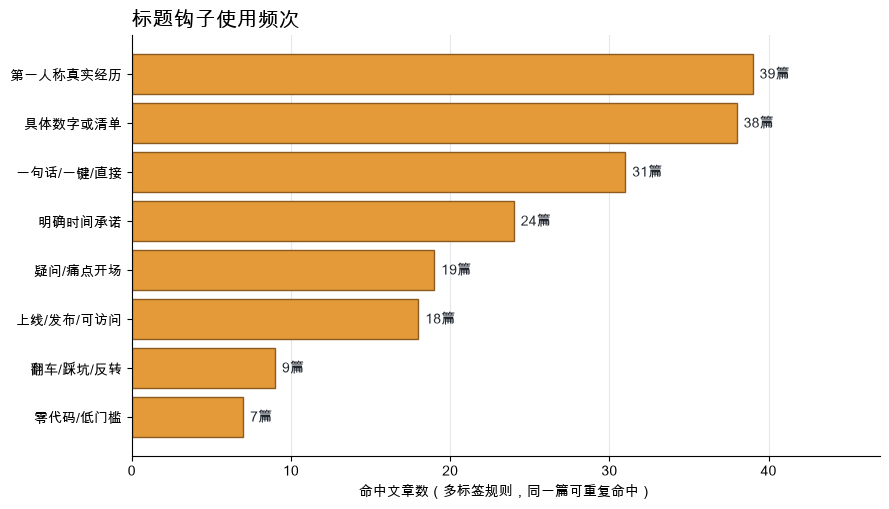

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.2))
plot_data = hook_summary.sort_values('articles')
bars = ax.barh(plot_data['hook'], plot_data['articles'], color='#E49A39', edgecolor='#8B5B1F')
ax.bar_label(bars, labels=[f'{v}篇' for v in plot_data['articles']], padding=5, color='#20262E')
ax.set_title('标题钩子使用频次', loc='left', fontsize=15, fontweight='bold')
ax.set_xlabel('命中文章数（多标签规则，同一篇可重复命中）')
ax.set_xlim(0, max(plot_data['articles']) + 8)
ax.grid(axis='x', color='#E5E7EB', linewidth=0.8)
ax.set_axisbelow(True)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT / '标题钩子.png', dpi=180, bbox_inches='tight')
plt.show()

### 8. Format and Conversion Signals

In [10]:
format_summary = pd.DataFrame({
    'signal': ['开头500字符出现真实人物/生活语境', '统一系列身份句', '统一关注CTA', '正文中声称持续日更', '标题含上线/发布结果'],
    'articles': [int(df['body_first_person'].sum()), int(df['has_series_cta'].sum()), int(df['has_follow_cta'].sum()),
                 int(df['has_daily_claim'].sum()), int(df['上线/发布/可访问'].sum())]
})
format_summary['share_pct'] = format_summary['articles'] / len(df) * 100
format_summary

,signal,articles,share_pct
0,开头500字符出现真实人物/生活语境,99,99.0
1,统一系列身份句,41,41.0
2,统一关注CTA,49,49.0
3,正文中声称持续日更,66,66.0
4,标题含上线/发布结果,18,18.0


In [11]:
distribution_summary = df[['char_count','image_count']].describe(percentiles=[.25,.5,.75]).round(1)
distribution_summary

,char_count,image_count
count,100.0,100.0
mean,2349.9,8.7
std,808.7,5.0
min,1122.0,1.0
25%,1852.8,6.0
50%,2259.5,8.0
75%,2668.0,11.0
max,4982.0,44.0


### 9. How the Series Evolved

In [12]:
df['series_phase'] = pd.cut(df['position'], [0,25,50,75,100], labels=['#1–25','#26–50','#51–75','#76–100'])
phase_summary = df.groupby('series_phase', observed=True).agg(
    articles=('position','count'),
    avg_chars=('char_count','mean'),
    avg_images=('image_count','mean'),
    first_person_title_share=('第一人称真实经历','mean'),
    time_promise_share=('明确时间承诺','mean'),
    standardized_series_line_share=('has_series_cta','mean'),
    standardized_follow_cta_share=('has_follow_cta','mean'),
).reset_index()
for column in ['first_person_title_share','time_promise_share','standardized_series_line_share','standardized_follow_cta_share']:
    phase_summary[column] = phase_summary[column] * 100
phase_summary.round(1)

,series_phase,articles,avg_chars,avg_images,first_person_title_share,time_promise_share,standardized_series_line_share,standardized_follow_cta_share
0,#1–25,25,2005.5,7.3,24.0,40.0,0.0,0.0
1,#26–50,25,2576.4,8.9,24.0,24.0,0.0,28.0
2,#51–75,25,2253.9,7.6,40.0,20.0,64.0,76.0
3,#76–100,25,2563.7,10.8,68.0,12.0,100.0,92.0


### 10. Candidate Video Topics

In [13]:
video_candidates = df.sort_values(['video_score','image_count'], ascending=False)[
    ['position','title_tail','primary_category','video_score','char_count','image_count']
].head(20)
video_candidates

,position,title_tail,primary_category,video_score,char_count,image_count
43,44,从没人像到带声音，我用WorkBuddy折腾出了30秒脱口秀视频,内容创作与传播,7,3182,15
44,45,折腾半天，终于让 AI 翻开了我的微信读书,研究、知识与决策,7,3142,11
72,73,我用AI帮朋友孩子报志愿，结果把自己吓一跳,研究、知识与决策,6,1529,15
81,82,AI帮我分析热点案件，报告还直接上线了,研究、知识与决策,6,2273,11
23,24,踩坑无数，我终于把ChatGPT Image 2接入了WorkBuddy,内容创作与传播,6,2269,9
96,97,想做个泡泡玛特发展史PPT还要能在线看？我把需求甩给WorkBuddy，它从生图到部署一条龙全包了,内容创作与传播,6,2012,9
2,3,零代码！语聊20分钟，2048游戏直接上线,开发与产品实现,6,1122,8
39,40,5分钟生成一份调查问卷并上线,办公与数据自动化,6,1383,8
87,88,我说要清内存，它却给我画了一套系统设计稿,开发与产品实现,6,1376,8
90,91,扔一句话过去，AI给我搭了个博客还直接上线了,开发与产品实现,6,1853,8


### 11. Export Reviewed Analysis Tables

In [14]:
export_columns = [
    'position','publish_date','title_actual','title_tail','primary_category','char_count','image_count',
    *hook_patterns.keys(), *capability_patterns.keys(), 'has_series_cta','has_follow_cta','has_daily_claim',
    'body_first_person','video_score','url','markdown_file','raw_html_file'
]
df[export_columns].to_csv(ROOT / 'analysis_features.csv', index=False, encoding='utf-8-sig')
category_summary.to_csv(OUTPUT / '主题分布.csv', index=False, encoding='utf-8-sig')
hook_summary.to_csv(OUTPUT / '标题钩子.csv', index=False, encoding='utf-8-sig')
format_summary.to_csv(OUTPUT / '格式与转化信号.csv', index=False, encoding='utf-8-sig')
phase_summary.to_csv(OUTPUT / '系列演进.csv', index=False, encoding='utf-8-sig')
video_candidates.to_csv(OUTPUT / '视频候选选题.csv', index=False, encoding='utf-8-sig')

summary = {
    'quality': quality_summary,
    'scale': dict(zip(scale_summary['metric'], scale_summary['value'])),
    'categories': category_summary.to_dict(orient='records'),
    'hooks': hook_summary.to_dict(orient='records'),
    'format_signals': format_summary.to_dict(orient='records'),
    'series_phases': phase_summary.round(2).to_dict(orient='records'),
    'char_count': {
        'mean': float(df['char_count'].mean()), 'median': float(df['char_count'].median()),
        'p25': float(df['char_count'].quantile(.25)), 'p75': float(df['char_count'].quantile(.75)),
    },
    'image_count': {
        'mean': float(df['image_count'].mean()), 'median': float(df['image_count'].median()),
        'p25': float(df['image_count'].quantile(.25)), 'p75': float(df['image_count'].quantile(.75)),
    },
    'top_video_candidates': video_candidates.to_dict(orient='records'),
}
(ROOT / 'analysis_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
summary['quality']

{'rows': 100,
 'unique_articles': 100,
 'failed_articles': 0,
 'start_date': '2026-04-01',
 'end_date': '2026-07-09',
 'calendar_days_inclusive': 100,
 'missing_publish_dates': [],
 'duplicate_publish_dates': [],
 'total_clean_chars': 234989,
 'total_inline_images': 866}

## Takeaways

- 这不是零散灵感集合，而是一套100个连续自然日的“真实场景—操作过程—具体结果”公开实验。
- 主题主力是内容传播、产品实现、办公自动化和研究决策；生活场景数量少，但能明显降低理解门槛，适合承担破圈入口。
- 标题普遍把抽象能力翻译成具体结果，并叠加时间、数字、疑问、低门槛或翻车反转；迁移时应保留“场景 + 结果 + 证据”，不能只复制夸张措辞。
- 系列身份句和关注CTA建立了连续追更，但原合集主要证明“能做什么”，对课程销售仍缺少系统承诺、适用人群、学习路径、学员证据与异议处理。
- 视频优先选择具备明显前后对比、可录屏过程、具象产物或真实翻车的主题；评分仅用于选题排队，最终仍需用发布数据验证。